# End-to-end 3D: predicted masks through the cloud pipeline

The final link of chapter 3. Notebooks 05–07 measured the 3D pipeline on
**ground-truth masks**; here the masks come from the trained segmentation model
— **Mask R-CNN, Detectron2 R101-FPN trained on the 20 min400 classes, dataset v2**
(the model selected by validation mask AP on the std10 validation split among all
v2 Mask R-CNN runs, notebook 10: val 0.2570, test 0.2665 on the 10 standard classes;
predictions file set by `PRED_PATH` below; only its predictions of the 10 standard
classes are used, as in the evaluator) —
so the numbers describe what the *application* actually delivers.

Configurations per matched test object, all through the identical cloud
pipeline (`utils/pointcloud.py`: mask refinement → back-projection → voxel +
SOR):

| | mask | depth | isolates |
|---|---|---|---|
| **A** | GT | sensor | reference (= notebooks 05/07) |
| **B** | predicted | sensor | segmentation error only |
| **C₁** | predicted | monocular, per-image `lstsq_disp` (oracle) | full pipeline, best case |
| **C₂** | predicted | monocular, **global** `lstsq_disp` | full pipeline, sensor-free |
| **C₃** | predicted | **metric** Depth Anything V2 Small + global scale | full pipeline, sensor-free |
| **C₄** | predicted | **metric** Depth Anything V2 Base + global scale | full pipeline, sensor-free |

B and every C are compared against A object-by-object: Chamfer distance,
centroid offset, distance-to-camera and size/volume errors. Together with
notebook 07 (depth error only) this factorises the total 3D error into its
two sources — and C₂–C₄ answer the question the web demo actually asks: which
depth backend should an RGB-only application use?

The notebook also contains the **ablation of the mask-refinement step** (the
boundary / discontinuity / outlier filtering introduced in `utils/pointcloud.py`),
measured on the full test split with the same A/B/C protocol. The last
section repeats the end-to-end evaluation on **all 20 classes** of the model
over the min400 test split.


In [1]:
import json, sys, time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import open3d as o3d
from pycocotools.coco import COCO
from pycocotools import mask as mask_utils

PROJECT_ROOT = Path.cwd().parent
sys.path.insert(0, str(PROJECT_ROOT))

import utils.sunrgbd as sd
import utils.pointcloud as pc

print("Open3D:", o3d.__version__)

Open3D: 0.19.0


In [2]:
# ---- parameters ------------------------------------------------------------
# test predictions of the SELECTED segmentation model (highest val mask AP among
# the dataset-v2 runs; COCO results format, RLE masks) — notebook 03 output
MODEL_NAME = "Mask R-CNN Detectron2 R101-FPN 3x (trained on min400, std10 classes; dataset v2)"
PRED_PATH  = Path.home() / "Downloads/v2_maskrcnn_detectron2_min400_R_101_FPN_3x/test_predictions.json"
# -----------------------------------------------------------------------------

DATASET_ROOT = Path("/Users/polina_sushko/My_work/University/ВКР/SUNRGBD")
SPLIT_DIR    = Path("outputs/splits")            # std10 config
OUT_DIR      = Path("outputs/eval3d_pred")

# monocular depth maps of the test split, all written by notebook 06 (float16 .npy)
MAP_DIRS = {
    "mono_oracle":        Path("outputs/depth_mono/maps"),                     # per-image lstsq_disp
    "mono_global":        Path("outputs/depth_mono/maps_global"),              # global lstsq_disp
    "metric_small_scale": Path("outputs/depth_mono/maps_metric_small_scale"),  # metric Small, global scale
    "metric_small_focal": Path("outputs/depth_mono/maps_metric_small_focal"),  # metric Small, focal scale
    "metric_base_scale":  Path("outputs/depth_mono/maps_metric_base_scale"),
    "metric_base_focal":  Path("outputs/depth_mono/maps_metric_base_focal"),
}
LABELS = {"mono_oracle": "mono, per-image (oracle)",
          "mono_global": "mono, global lstsq_disp",
          "metric_small_scale": "metric Small + global scale",
          "metric_small_focal": "metric Small + focal scale",
          "metric_base_scale": "metric Base + global scale",
          "metric_base_focal": "metric Base + focal scale"}
DEPLOYABLE = [v for v in MAP_DIRS if v != "mono_oracle"]

# matching protocol — must mirror evaluate_predictions.py
CONF_THRESH = 0.5
IOU_THRESH  = 0.5

MIN_POINTS = pc.MIN_POINTS   # per cloud; an object is kept only if ALL its clouds pass
print(f"cloud pipeline: voxel {pc.VOXEL_SIZE} m, SOR ({pc.SOR_NEIGHBORS}, {pc.SOR_STD_RATIO}), "
      f"min points {MIN_POINTS}; refinement: erode {pc.ERODE_PX} px, edge window "
      f"{pc.EDGE_WINDOW} px, MAD k = {pc.DEPTH_MAD_K}")

SENSOR_COLOR = "#2a78d6"     # blue   = predicted mask + sensor depth (B)
MONO_COLOR   = "#eb6834"     # orange = predicted mask + monocular depth (C)
VARIANT_COLORS = {"mono_oracle": "#eb6834", "mono_global": "#f2b07a",
                  "metric_small_scale": "#9bd38a", "metric_small_focal": "#6aa84f",
                  "metric_base_scale": "#3f8a3f", "metric_base_focal": "#1f4f1f"}

OUT_DIR.mkdir(parents=True, exist_ok=True)
version = json.loads((SPLIT_DIR / "dataset_version.json").read_text())["version"]
assert version == "v2", f"expected dataset v2 splits, found {version}"
print(f"model: {MODEL_NAME}\npredictions: {PRED_PATH}\ndataset: {version}")
coco = COCO(str(SPLIT_DIR / "instances_test.json"))
cat_name = {c["id"]: c["name"] for c in coco.loadCats(coco.getCatIds())}
img_ids = sorted(coco.getImgIds())

VARIANTS = [v for v, d in MAP_DIRS.items()
            if all((d / f"{i}.npy").exists() for i in img_ids)]
missing = [v for v in MAP_DIRS if v not in VARIANTS]
print(f"depth variants with complete maps: {VARIANTS}" + (f" (missing: {missing})" if missing else ""))

# a min400 model also predicts 10 extra classes (ids 11-20) and has predictions on
# min400-only images: both are dropped, exactly as the evaluator's loader does
_img_set = set(img_ids)
with open(PRED_PATH) as f:
    predictions = [p for p in json.load(f) if p["score"] >= CONF_THRESH
                   and p["category_id"] in cat_name and p["image_id"] in _img_set]
preds_by_img = {}
for p in predictions:
    preds_by_img.setdefault(p["image_id"], []).append(p)
print(f"Predictions with conf >= {CONF_THRESH}: {len(predictions)} "
      f"on {len(preds_by_img)} images")


cloud pipeline: voxel 0.02 m, SOR (20, 2.0), min points 100; refinement: erode 2 px, edge window 5 px, MAD k = 3.0
model: Mask R-CNN Detectron2 R101-FPN 3x (trained on min400, std10 classes; dataset v2)
predictions: /Users/polina_sushko/Downloads/v2_maskrcnn_detectron2_min400_R_101_FPN_3x/test_predictions.json
dataset: v2
loading annotations into memory...
Done (t=0.02s)
creating index...
index created!
depth variants with complete maps: ['mono_oracle', 'mono_global', 'metric_small_scale', 'metric_small_focal', 'metric_base_scale', 'metric_base_focal']


Predictions with conf >= 0.5: 5619 on 1230 images


---
## Matching and paired clouds

Predictions are matched to GT exactly as in `evaluate_predictions.py`: greedily
by descending score, class-agnostic mask IoU >= 0.5 — so a well-localised but
misclassified object still gets its 3D geometry evaluated (the
`correct_class` flag keeps the distinction). Unmatched predictions (FP) and
unmatched GT (FN) have no reference / no estimate and are counted, not
measured — the segmentation notebooks already quantify them.

**Footprints.** Every cloud of an object is built on the pixels that
`pc.refine_mask()` accepts in *all* depth maps of the comparison (sensor and
every monocular variant), intersected: one footprint for the GT mask (cloud A)
and one for the predicted mask (B and all C's). B therefore differs from A only
by the mask, and every C differs from B only by the depth source — the same
principle as notebook 07, extended to several depth variants at once.


In [3]:
def load_maps(img_info: dict, variants):
    """Sensor depth, the requested monocular maps and intrinsics for one image."""
    d_sen = sd.read_depth(DATASET_ROOT / img_info["depth_file"])
    d_mono = {v: np.load(MAP_DIRS[v] / f"{img_info['id']}.npy").astype(np.float32)
              for v in variants}
    intr = sd.Intrinsics(fx=img_info["fx"], fy=img_info["fy"],
                         cx=img_info["cx"], cy=img_info["cy"])
    return d_sen, d_mono, intr


def compare_to_ref(pcd, ref_pcd, m, m_ref, prefix: str) -> dict:
    """Error metrics of one estimated cloud vs the reference cloud A."""
    return {
        f"{prefix}_chamfer_cm": pc.chamfer_cm(pcd, ref_pcd),
        f"{prefix}_centroid_offset_cm": 100.0 * float(
            np.linalg.norm(m["centroid"] - m_ref["centroid"])),
        f"{prefix}_dist_err_m": m["dist_to_camera_m"] - m_ref["dist_to_camera_m"],
        f"{prefix}_obb_extent_1_pct_err": pc.pct_err(m["obb_extent_1"], m_ref["obb_extent_1"]),
        f"{prefix}_obb_volume_pct_err": pc.pct_err(m["obb_volume_m3"], m_ref["obb_volume_m3"]),
        f"{prefix}_hull_volume_pct_err": pc.pct_err(m["hull_volume_m3"], m_ref["hull_volume_m3"]),
        f"{prefix}_n_points": m["n_points"],
    }


def match_image(img_id: int):
    """Greedy class-agnostic matching, mirroring evaluate_predictions.py."""
    gts = coco.loadAnns(coco.getAnnIds(imgIds=img_id, iscrowd=False))
    dts = sorted(preds_by_img.get(img_id, []), key=lambda p: -p["score"])
    gt_rles = [coco.annToRLE(a) for a in gts]
    dt_rles = [d["segmentation"] for d in dts]
    if not (gt_rles and dt_rles):
        return []
    ious = mask_utils.iou(dt_rles, gt_rles, [0] * len(gt_rles))
    pairs, gt_used = [], set()
    for di, d in enumerate(dts):
        best_gi, best_iou = -1, IOU_THRESH
        for gi in range(len(gts)):
            if gi not in gt_used and ious[di, gi] >= best_iou:
                best_gi, best_iou = gi, ious[di, gi]
        if best_gi >= 0:
            gt_used.add(best_gi)
            pairs.append((gts[best_gi], d, float(best_iou)))
    return pairs


def process_image(img_id: int, variants=None, refine_kwargs: dict | None = None):
    """A / B / C-per-variant clouds and error metrics for every matched object."""
    variants = VARIANTS if variants is None else variants
    kw = refine_kwargs or {}
    pairs = match_image(img_id)
    if not pairs:
        return []
    info = coco.loadImgs(img_id)[0]
    d_sen, d_mono, intr = load_maps(info, variants)
    maps = [d_sen] + [d_mono[v] for v in variants]
    rows = []
    for gt, dt, iou in pairs:
        gt_mask = coco.annToMask(gt).astype(bool)
        dt_mask = mask_utils.decode(dt["segmentation"]).astype(bool)
        fp_gt = np.logical_and.reduce([pc.refine_mask(gt_mask, m, **kw) for m in maps])
        fp_dt = np.logical_and.reduce([pc.refine_mask(dt_mask, m, **kw) for m in maps])
        pcd_a = pc.build_cloud(d_sen, intr, fp_gt, refine=False)
        pcd_b = pc.build_cloud(d_sen, intr, fp_dt, refine=False)
        pcd_c = {v: pc.build_cloud(d_mono[v], intr, fp_dt, refine=False) for v in variants}
        if min(len(pcd_a.points), len(pcd_b.points),
               *(len(p.points) for p in pcd_c.values())) < MIN_POINTS:
            continue
        ma, mb = pc.object_3d_metrics(pcd_a), pc.object_3d_metrics(pcd_b)
        row = {
            "image_id": img_id, "gt_ann_id": gt["id"],
            "class": cat_name[gt["category_id"]],
            "pred_class": cat_name[dt["category_id"]],
            "correct_class": gt["category_id"] == dt["category_id"],
            "score": dt["score"], "mask_iou": iou,
            "sensor": info["sensor"],
            "dist_ref_m": ma["dist_to_camera_m"],
            "ref_n_points": ma["n_points"],
            "ref_obb_extent_3_m": ma["obb_extent_3"],
            "ref_obb_volume_m3": ma["obb_volume_m3"],
            **compare_to_ref(pcd_b, pcd_a, mb, ma, "segm"),
        }
        for v in variants:
            mc = pc.object_3d_metrics(pcd_c[v])
            row.update(compare_to_ref(pcd_c[v], pcd_a, mc, ma, v))
        rows.append(row)
    return rows


---
## Ablation: mask refinement

The refinement step of `pc.refine_mask()` is switched on stage by stage
(boundary erosion → depth-discontinuity filter → per-object depth outliers) on
the full test split, with the oracle monocular maps as C. Three things are
measured: the **cost** — how many matched objects survive `MIN_POINTS`; the
**curtain indicator** — the smallest OBB extent of the reference cloud A (a
visible surface should be thin; points streaking towards the background thicken
it); and the **effect on the errors** of B and C against A. The reference A is
refined too, so the Chamfer numbers of different rows are not on the same
reference — the thickness column and the volume errors are the direct evidence.


In [4]:
ABLATION = {
    "none (first-version pipeline)": dict(erode_px=0, edge_filter=False, mad_k=None),
    "erode 2 px":                    dict(erode_px=pc.ERODE_PX, edge_filter=False, mad_k=None),
    "+ depth discontinuities":       dict(erode_px=pc.ERODE_PX, edge_filter=True, mad_k=None),
    "+ depth outliers (default)":    dict(erode_px=pc.ERODE_PX, edge_filter=True, mad_k=pc.DEPTH_MAD_K),
}
ABL_VARIANT = "mono_oracle"
abl_rows = []
for name, kw in ABLATION.items():
    t0 = time.time()
    rows = []
    for img_id in img_ids:
        rows.extend(process_image(img_id, variants=[ABL_VARIANT], refine_kwargs=kw))
    a = pd.DataFrame(rows)
    abl_rows.append({
        "refinement": name, "n_objects": len(a),
        "A_points_median": a.ref_n_points.median(),
        "A_thickness_cm": 100 * a.ref_obb_extent_3_m.median(),
        "A_obb_volume_m3": a.ref_obb_volume_m3.median(),
        "B_chamfer_cm": a.segm_chamfer_cm.median(),
        "B_abs_vol_err_pct": a.segm_obb_volume_pct_err.abs().median(),
        "C_chamfer_cm": a[f"{ABL_VARIANT}_chamfer_cm"].median(),
        "C_abs_vol_err_pct": a[f"{ABL_VARIANT}_obb_volume_pct_err"].abs().median(),
        "C_abs_dist_err_m": a[f"{ABL_VARIANT}_dist_err_m"].abs().median(),
    })
    print(f"  {name:31s} {len(a):5d} objects  ({time.time() - t0:.0f} s)")

ablation = pd.DataFrame(abl_rows).set_index("refinement").round(2)
ablation.to_csv(OUT_DIR / "refinement_ablation.csv")
ablation


  none (first-version pipeline)    2879 objects  (78 s)


  erode 2 px                       2841 objects  (87 s)


  + depth discontinuities          2776 objects  (156 s)


  + depth outliers (default)       2746 objects  (172 s)


,n_objects,A_points_median,A_thickness_cm,A_obb_volume_m3,B_chamfer_cm,B_abs_vol_err_pct,C_chamfer_cm,C_abs_vol_err_pct,C_abs_dist_err_m
refinement,,,,,,,,,
none (first-version pipeline),2879,2439.0,56.97,0.81,1.69,26.33,10.34,55.13,0.17
erode 2 px,2841,2154.0,52.17,0.64,1.65,28.75,10.65,60.82,0.17
+ depth discontinuities,2776,1499.5,44.69,0.39,1.14,22.77,10.99,60.00,0.15
+ depth outliers (default),2746,1357.0,39.27,0.25,0.88,19.39,9.22,54.50,0.13


---
## Batch over the full test split

In [5]:
all_rows = []
t0 = time.time()
for n, img_id in enumerate(img_ids, 1):
    all_rows.extend(process_image(img_id))
    if n % 50 == 0 or n == len(img_ids):
        print(f"  {n}/{len(img_ids)} images, {len(all_rows)} matched objects "
              f"({n / (time.time() - t0):.2f} img/s)", end="\r")
print()

df = pd.DataFrame(all_rows)
df.to_csv(OUT_DIR / "object_metrics_pred_masks.csv", index=False)
print(f"Matched objects with valid clouds in every configuration: {len(df)} "
      f"on {df.image_id.nunique()} images ({time.time() - t0:.0f} s)")
print(f"Correctly classified among them: {df.correct_class.mean():.1%}; "
      f"median mask IoU: {df.mask_iou.median():.3f}")


  1287/1287 images, 2580 matched objects (2.47 img/s)
Matched objects with valid clouds in every configuration: 2580 on 1080 images (522 s)
Correctly classified among them: 89.9%; median mask IoU: 0.826


---
## Detection-level outcome (what never reaches the 3D table)

The same predictions at the same operating point, counted with the evaluator's
own function (`evaluate_predictions.pr_f1_confusion`: class-aware TP, a
localised but misclassified prediction is one FP + one FN), plus the
class-agnostic split that matters for the 3D scene: phantom objects (a
prediction matching no GT) and objects missing from the scene entirely.

In [6]:
from utils.evaluate_predictions import pr_f1_confusion

det_table, _, _, det_mean_iou = pr_f1_confusion(coco, predictions, CONF_THRESH, IOU_THRESH)
micro = det_table.loc["micro avg"]
print(f"{MODEL_NAME}, test, conf >= {CONF_THRESH}, mask IoU >= {IOU_THRESH}:")
print(f"  class-aware: TP {int(micro.TP)}, FP {int(micro.FP)}, FN {int(micro.FN)}; "
      f"P {micro.precision:.3f}, R {micro.recall:.3f}, F1 {micro.F1:.3f}; "
      f"mean matched IoU {det_mean_iou:.3f}")

n_matched = sum(len(match_image(i)) for i in img_ids)
n_gt = len(coco.getAnnIds(imgIds=img_ids, iscrowd=False))
print(f"  class-agnostic: {n_matched} matched pairs, {len(predictions) - n_matched} phantom "
      f"predictions (no GT with IoU >= {IOU_THRESH}), {n_gt - n_matched} of {n_gt} GT "
      f"objects missed; matched pairs with valid clouds in all configurations: {len(df)}")

Mask R-CNN Detectron2 R101-FPN 3x (trained on min400, std10 classes; dataset v2), test, conf >= 0.5, mask IoU >= 0.5:
  class-aware: TP 2642, FP 2977, FN 2401; P 0.470, R 0.524, F1 0.496; mean matched IoU 0.790
  class-agnostic: 2929 matched pairs, 2690 phantom predictions (no GT with IoU >= 0.5), 2114 of 5043 GT objects missed; matched pairs with valid clouds in all configurations: 2580


---
## Summary: segmentation error vs full pipeline, per depth backend

`B` = predicted mask on sensor depth (segmentation error only); every `C` =
predicted mask on one monocular depth variant (full pipeline). The depth-only
counterpart (GT mask, oracle monocular depth) is notebook 07.


In [7]:
METRICS = ["chamfer_cm", "centroid_offset_cm", "dist_err_m",
           "obb_extent_1_pct_err", "obb_volume_pct_err", "hull_volume_pct_err"]
CONFIGS = {"B: pred + sensor": "segm", **{f"C: pred + {LABELS[v]}": v for v in VARIANTS}}

blocks = {}
for label, prefix in CONFIGS.items():
    sub = df[[f"{prefix}_{m}" for m in METRICS]].set_axis(METRICS, axis=1)
    blocks[(label, "median_signed")] = sub.median()
    blocks[(label, "median_abs")] = sub.abs().median()
summary = pd.DataFrame(blocks).round(2)
summary.to_csv(OUT_DIR / "summary_pred_masks.csv")

best_deployable = min((v for v in DEPLOYABLE if v in VARIANTS),
                      key=lambda v: df[f"{v}_chamfer_cm"].median(), default=None)
print(f"Best sensor-free depth backend by median Chamfer: {best_deployable} "
      f"({LABELS.get(best_deployable, '-')})")
summary


Best sensor-free depth backend by median Chamfer: metric_base_scale (metric Base + global scale)


B: pred + sensor             \
                        median_signed median_abs   
chamfer_cm                       0.82       0.82   
centroid_offset_cm               2.47       2.47   
dist_err_m                      -0.00       0.01   
obb_extent_1_pct_err            -0.35       4.09   
obb_volume_pct_err              -2.25      17.58   
hull_volume_pct_err             -2.38      16.25   

                     C: pred + mono, per-image (oracle)             \
                                          median_signed median_abs   
chamfer_cm                                         8.85       8.85   
centroid_offset_cm                                14.34      14.34   
dist_err_m                                        -0.06       0.12   
obb_extent_1_pct_err                              -8.89      14.21   
obb_volume_pct_err                               -42.66      55.95   
hull_volume_pct_err                              -45.69      55.77   

                     C: pred + mono, global lstsq_disp             \
                                         median_signed median_abs   
chamfer_cm                                       24.97      24.97   
centroid_offset_cm                               40.39      40.39   
dist_err_m                                       -0.30       0.39   
obb_extent_1_pct_err                            -20.93      25.00   
obb_volume_pct_err                              -60.90      68.80   
hull_volume_pct_err                             -63.91      70.19   

                     C: pred + metric Small + global scale             \
                                             median_signed median_abs   
chamfer_cm                                           15.15      15.15   
centroid_offset_cm                                   25.78      25.78   
dist_err_m                                            0.05       0.24   
obb_extent_1_pct_err                                 -0.45      16.27   
obb_volume_pct_err                                  -11.81      49.40   
hull_volume_pct_err                                 -11.73      47.85   

                     C: pred + metric Small + focal scale             \
                                            median_signed median_abs   
chamfer_cm                                          20.35      20.35   
centroid_offset_cm                                  35.05      35.05   
dist_err_m                                          -0.09       0.33   
obb_extent_1_pct_err                                -7.89      20.20   
obb_volume_pct_err                                 -27.85      58.24   
hull_volume_pct_err                                -29.39      58.28   

                     C: pred + metric Base + global scale             \
                                            median_signed median_abs   
chamfer_cm                                          13.25      13.25   
centroid_offset_cm                                  22.41      22.41   
dist_err_m                                           0.06       0.21   
obb_extent_1_pct_err                                -0.11      14.38   
obb_volume_pct_err                                 -10.41      44.88   
hull_volume_pct_err                                -11.31      43.14   

                     C: pred + metric Base + focal scale             
                                           median_signed median_abs  
chamfer_cm                                         16.69      16.69  
centroid_offset_cm                                 28.96      28.96  
dist_err_m                                         -0.10       0.28  
obb_extent_1_pct_err                               -8.77      17.70  
obb_volume_pct_err                                -28.20      53.09  
hull_volume_pct_err                               -30.14      52.77

In [8]:
# breakdowns: object distance, segmentation quality and class, per depth backend
CH = ["segm_chamfer_cm"] + [f"{v}_chamfer_cm" for v in VARIANTS]
df["dist_bin"] = pd.cut(df.dist_ref_m, [0, 1.5, 2.5, 3.5, 5, 8],
                        labels=["<1.5 m", "1.5–2.5 m", "2.5–3.5 m", "3.5–5 m", ">5 m"])
df["iou_bin"] = pd.cut(df.mask_iou, [0.5, 0.7, 0.85, 1.0],
                       labels=["IoU 0.5–0.7", "0.7–0.85", "0.85–1.0"])

by_distance = df.groupby("dist_bin", observed=True)[CH].median().round(2)
by_distance["n_objects"] = df.groupby("dist_bin", observed=True).size()
by_iou = df.groupby("iou_bin", observed=True)[CH].median().round(2)
by_iou["n_objects"] = df.groupby("iou_bin", observed=True).size()
by_class = df.groupby("class")[CH + ["mask_iou"]].median().round(2)
by_class["n_objects"] = df.groupby("class").size()
by_class = by_class.sort_values("mono_oracle_chamfer_cm" if "mono_oracle" in VARIANTS else CH[-1])
by_sensor = df.groupby("sensor")[CH].median().round(2)
by_sensor["n_objects"] = df.groupby("sensor").size()

by_distance.to_csv(OUT_DIR / "breakdown_distance.csv")
by_iou.to_csv(OUT_DIR / "breakdown_iou.csv")
by_class.to_csv(OUT_DIR / "breakdown_class.csv")
by_sensor.to_csv(OUT_DIR / "breakdown_sensor.csv")
print("Median Chamfer (cm) by distance:"); print(by_distance, "\n")
print("By mask IoU:"); print(by_iou, "\n")
print("By sensor:"); print(by_sensor, "\n")
print("By class:"); print(by_class)


Median Chamfer (cm) by distance:
           segm_chamfer_cm  mono_oracle_chamfer_cm  mono_global_chamfer_cm  \
dist_bin                                                                     
<1.5 m                0.83                    5.01                   13.26   
1.5–2.5 m             0.91                    7.04                   15.68   
2.5–3.5 m             0.71                   13.43                   44.88   
3.5–5 m               0.72                   34.26                  108.43   
>5 m                  0.79                  104.13                  221.49   

           metric_small_scale_chamfer_cm  metric_small_focal_chamfer_cm  \
dist_bin                                                                  
<1.5 m                             11.85                          13.02   
1.5–2.5 m                          12.39                          16.47   
2.5–3.5 m                          19.29                          30.86   
3.5–5 m                            28.30     

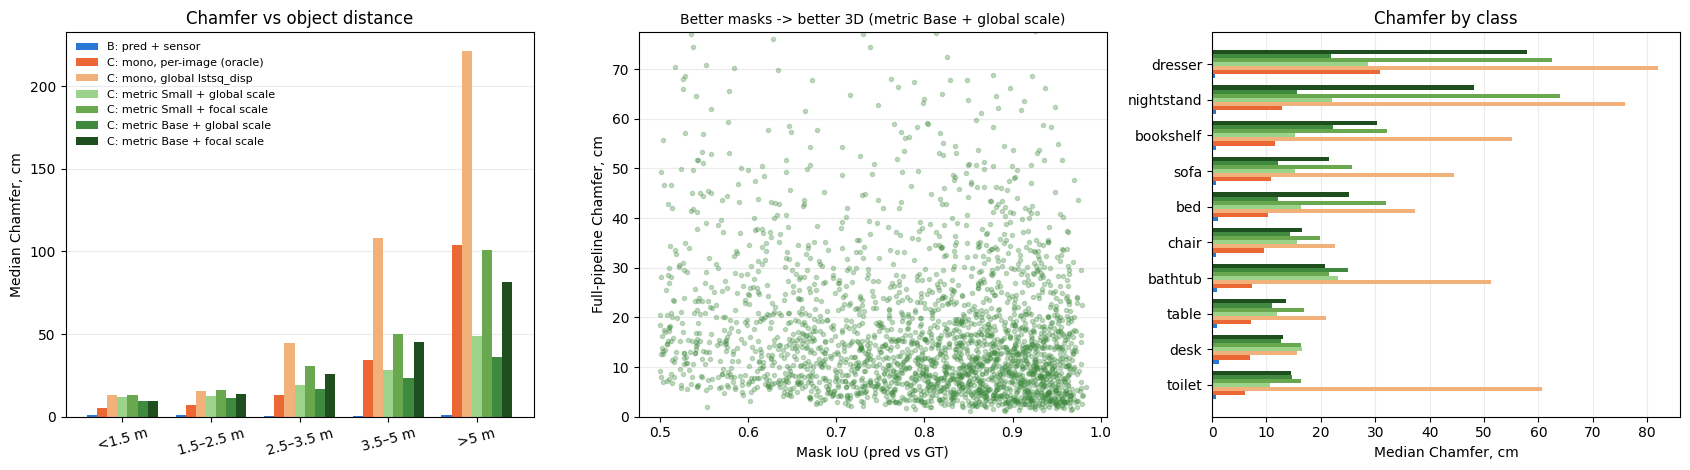

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
series = [("segm", "B: pred + sensor", SENSOR_COLOR)] + \
         [(v, f"C: {LABELS[v]}", VARIANT_COLORS[v]) for v in VARIANTS]
w = 0.8 / len(series)

x = np.arange(len(by_distance))
for i, (prefix, label, color) in enumerate(series):
    axes[0].bar(x + (i - len(series) / 2 + 0.5) * w, by_distance[f"{prefix}_chamfer_cm"],
                w, color=color, label=label)
axes[0].set_xticks(x, by_distance.index, rotation=15)
axes[0].set_ylabel("Median Chamfer, cm"); axes[0].set_title("Chamfer vs object distance")
axes[0].legend(frameon=False, fontsize=8)

show = best_deployable or VARIANTS[-1]
axes[1].scatter(df.mask_iou, df[f"{show}_chamfer_cm"], s=9, c=VARIANT_COLORS[show], alpha=0.3)
axes[1].set_xlabel("Mask IoU (pred vs GT)"); axes[1].set_ylabel("Full-pipeline Chamfer, cm")
axes[1].set_ylim(0, np.nanpercentile(df[f"{show}_chamfer_cm"], 98))
axes[1].set_title(f"Better masks -> better 3D ({LABELS[show]})", fontsize=10)

y = np.arange(len(by_class))
for i, (prefix, label, color) in enumerate(series):
    axes[2].barh(y + (i - len(series) / 2 + 0.5) * w, by_class[f"{prefix}_chamfer_cm"],
                 w, color=color, label=label)
axes[2].set_yticks(y, by_class.index); axes[2].set_xlabel("Median Chamfer, cm")
axes[2].set_title("Chamfer by class")

for ax in axes:
    ax.grid(axis="x" if ax is axes[2] else "y", alpha=0.25)
    ax.set_axisbelow(True)
plt.tight_layout()
plt.savefig(OUT_DIR / "pred_masks_breakdown.png", dpi=150, bbox_inches="tight")
plt.show()


---
## All 20 classes (min400 test split)

The selected model was trained on 20 classes, and the web demo shows all 20, but
the sections above measure only the 10 standard ones. Here the same protocol runs
on the **min400 test split** (1444 images: the std10 test split plus 157 images
whose GT holds only extra classes; their monocular maps come from the last section
of notebook 06) with **all 20 classes** of the predictions. Matching, refinement,
the common seven-map footprint and every depth variant are unchanged; only the GT
file and the class filter differ. Results are reported per class group (the 10
standard classes vs the 10 extra ones) and per class; the std10 run above is kept
as the reference row.

In [10]:
# ---- 20-class evaluation set ------------------------------------------------
# match_image() / process_image() read the module-level `coco`, `cat_name` and
# `preds_by_img`. The std10 results above are complete and on disk, so these names
# are rebound here to the min400 test split and all 20 classes of the model
MODEL_NAME_20 = "Mask R-CNN Detectron2 R101-FPN 3x (trained on min400, all 20 classes; dataset v2)"
SPLIT_DIR_20 = Path("outputs/splits_min400")
version_20 = json.loads((SPLIT_DIR_20 / "dataset_version.json").read_text())["version"]
assert version_20 == "v2", f"expected dataset v2 splits, found {version_20}"

df_std10, cat_name_std10 = df, cat_name
coco = COCO(str(SPLIT_DIR_20 / "instances_test.json"))
cat_name = {c["id"]: c["name"] for c in coco.loadCats(coco.getCatIds())}
assert all(cat_name[k] == n for k, n in cat_name_std10.items()), "std10 ids must be shared"
img_ids_20 = sorted(coco.getImgIds())
no_maps = [v for v in VARIANTS if not all((MAP_DIRS[v] / f"{i}.npy").exists() for i in img_ids_20)]
assert not no_maps, f"maps missing for min400-only test images in {no_maps}: run notebook 06"

_img_set_20 = set(img_ids_20)
with open(PRED_PATH) as f:
    predictions_20 = [p for p in json.load(f) if p["score"] >= CONF_THRESH
                      and p["category_id"] in cat_name and p["image_id"] in _img_set_20]
preds_by_img = {}
for p in predictions_20:
    preds_by_img.setdefault(p["image_id"], []).append(p)
print(f"min400 test: {len(img_ids_20)} images, {len(coco.getAnnIds(iscrowd=False))} GT objects, "
      f"{len(cat_name)} classes; predictions with conf >= {CONF_THRESH}: {len(predictions_20)}")

rows_20 = []
t0 = time.time()
for n, img_id in enumerate(img_ids_20, 1):
    rows_20.extend(process_image(img_id))
    if n % 50 == 0 or n == len(img_ids_20):
        print(f"  {n}/{len(img_ids_20)} images, {len(rows_20)} matched objects "
              f"({n / (time.time() - t0):.2f} img/s)", end="\r")
print()

df20 = pd.DataFrame(rows_20)
df20["class_group"] = np.where(df20["class"].isin(set(cat_name_std10.values())), "std10", "extra")
df20.to_csv(OUT_DIR / "object_metrics_pred_masks_min400.csv", index=False)
print(f"Matched objects with valid clouds in every configuration: {len(df20)} "
      f"on {df20.image_id.nunique()} images ({time.time() - t0:.0f} s)")
df20.groupby("class_group").agg(n_objects=("class", "size"),
                                correct_class=("correct_class", "mean"),
                                median_mask_iou=("mask_iou", "median"),
                                median_dist_m=("dist_ref_m", "median")).round(3)

loading annotations into memory...
Done (t=0.02s)
creating index...
index created!


min400 test: 1444 images, 7517 GT objects, 20 classes; predictions with conf >= 0.5: 8380


  1444/1444 images, 3586 matched objects (2.03 img/s)
Matched objects with valid clouds in every configuration: 3586 on 1276 images (711 s)


,n_objects,correct_class,median_mask_iou,median_dist_m
class_group,,,,
extra,965,0.891,0.850,2.573
std10,2621,0.883,0.826,2.218


In [11]:
det_table_20, _, _, det_mean_iou_20 = pr_f1_confusion(coco, predictions_20, CONF_THRESH, IOU_THRESH)
micro_20 = det_table_20.loc["micro avg"]
print(f"{MODEL_NAME_20}, min400 test, conf >= {CONF_THRESH}, mask IoU >= {IOU_THRESH}:")
print(f"  class-aware: TP {int(micro_20.TP)}, FP {int(micro_20.FP)}, FN {int(micro_20.FN)}; "
      f"P {micro_20.precision:.3f}, R {micro_20.recall:.3f}, F1 {micro_20.F1:.3f}; "
      f"mean matched IoU {det_mean_iou_20:.3f}")

n_matched_20 = sum(len(match_image(i)) for i in img_ids_20)
n_gt_20 = len(coco.getAnnIds(imgIds=img_ids_20, iscrowd=False))
print(f"  class-agnostic: {n_matched_20} matched pairs, {len(predictions_20) - n_matched_20} phantom "
      f"predictions (no GT with IoU >= {IOU_THRESH}), {n_gt_20 - n_matched_20} of {n_gt_20} GT "
      f"objects missed; matched pairs with valid clouds in all configurations: {len(df20)}")
det_table_20.to_csv(OUT_DIR / "detection_min400.csv")
det_table_20

Mask R-CNN Detectron2 R101-FPN 3x (trained on min400, all 20 classes; dataset v2), min400 test, conf >= 0.5, mask IoU >= 0.5:
  class-aware: TP 3697, FP 4683, FN 3820; P 0.441, R 0.492, F1 0.465; mean matched IoU 0.795


  class-agnostic: 4176 matched pairs, 4204 phantom predictions (no GT with IoU >= 0.5), 3341 of 7517 GT objects missed; matched pairs with valid clouds in all configurations: 3586


,precision,recall,F1,TP,FP,FN
bed,0.5075,0.6126,0.5551,136.0,132.0,86.0
chair,0.4665,0.5892,0.5208,1562.0,1786.0,1089.0
sofa,0.3934,0.4769,0.4312,155.0,239.0,170.0
table,0.4699,0.5455,0.5049,617.0,696.0,514.0
desk,0.3462,0.0945,0.1485,36.0,68.0,345.0
toilet,0.6591,0.7436,0.6988,29.0,15.0,10.0
dresser,0.5238,0.4356,0.4757,44.0,40.0,57.0
nightstand,0.4444,0.3226,0.3738,20.0,25.0,42.0
bookshelf,0.4603,0.2661,0.3372,29.0,34.0,80.0
bathtub,0.3226,0.4545,0.3774,10.0,21.0,12.0


In [12]:
def group_summary(frame: pd.DataFrame) -> pd.DataFrame:
    """Median errors of one set of objects, one row per configuration."""
    return pd.DataFrame({label: {
        "n_objects": len(frame),
        "median_dist_m": frame.dist_ref_m.median(),
        "chamfer_cm": frame[f"{prefix}_chamfer_cm"].median(),
        "centroid_offset_cm": frame[f"{prefix}_centroid_offset_cm"].median(),
        "abs_dist_err_m": frame[f"{prefix}_dist_err_m"].abs().median(),
        "obb_volume_pct_err": frame[f"{prefix}_obb_volume_pct_err"].median(),
        "abs_obb_volume_pct_err": frame[f"{prefix}_obb_volume_pct_err"].abs().median(),
    } for label, prefix in CONFIGS.items()}).T


GROUPS = {"all 20 classes": df20,
          "std10 classes": df20[df20.class_group == "std10"],
          "10 extra classes": df20[df20.class_group == "extra"],
          "std10 run (sections above)": df_std10}
summary_20 = pd.concat({g: group_summary(f) for g, f in GROUPS.items()}).round(2)
summary_20.to_csv(OUT_DIR / "summary_pred_masks_min400.csv")

by_class_20 = df20.groupby("class")[CH + ["mask_iou", "dist_ref_m"]].median().round(2)
by_class_20["n_objects"] = df20.groupby("class").size()
by_class_20["extra_class"] = ~by_class_20.index.isin(set(cat_name_std10.values()))
by_class_20 = by_class_20.sort_values("mono_oracle_chamfer_cm" if "mono_oracle" in VARIANTS else CH[-1])
by_class_20.to_csv(OUT_DIR / "breakdown_class_min400.csv")

print("Median Chamfer (cm) per class group:")
print(summary_20.chamfer_cm.unstack(0)[list(GROUPS)], "\n")
print("Median |OBB volume error| (%) per class group:")
print(summary_20.abs_obb_volume_pct_err.unstack(0)[list(GROUPS)], "\n")
print("By class (extra_class = not in std10):")
print(by_class_20)

Median Chamfer (cm) per class group:
                                       all 20 classes  std10 classes  \
B: pred + sensor                                 0.78           0.81   
C: pred + mono, per-image (oracle)               8.83           8.81   
C: pred + mono, global lstsq_disp               27.97          25.03   
C: pred + metric Small + global scale           15.82          15.12   
C: pred + metric Small + focal scale            21.74          20.41   
C: pred + metric Base + global scale            13.61          13.26   
C: pred + metric Base + focal scale             17.92          16.73   

                                       10 extra classes  \
B: pred + sensor                                   0.72   
C: pred + mono, per-image (oracle)                 8.91   
C: pred + mono, global lstsq_disp                 37.38   
C: pred + metric Small + global scale             18.82   
C: pred + metric Small + focal scale              27.04   
C: pred + metric Base + global s

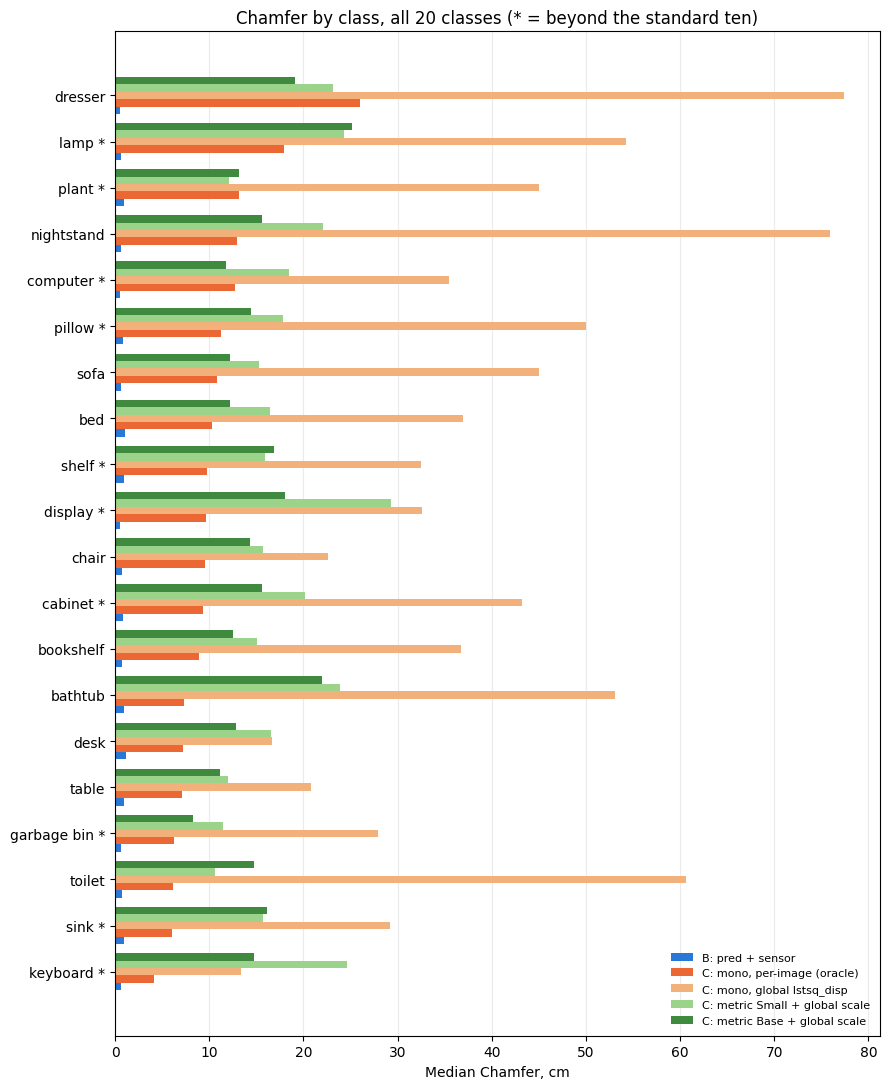

In [13]:
PLOT_20 = [("segm", "B: pred + sensor", SENSOR_COLOR)] + \
          [(v, f"C: {LABELS[v]}", VARIANT_COLORS[v])
           for v in ("mono_oracle", "mono_global", "metric_small_scale", "metric_base_scale")
           if v in VARIANTS]
w = 0.8 / len(PLOT_20)
fig, ax = plt.subplots(figsize=(9, 11))
y = np.arange(len(by_class_20))
for i, (prefix, label, color) in enumerate(PLOT_20):
    ax.barh(y + (i - len(PLOT_20) / 2 + 0.5) * w, by_class_20[f"{prefix}_chamfer_cm"],
            w, color=color, label=label)
ax.set_yticks(y, [f"{k} *" if extra else k
                  for k, extra in zip(by_class_20.index, by_class_20.extra_class)])
ax.set_xlabel("Median Chamfer, cm")
ax.set_title("Chamfer by class, all 20 classes (* = beyond the standard ten)")
ax.legend(frameon=False, fontsize=8, loc="lower right")
ax.grid(axis="x", alpha=0.25)
ax.set_axisbelow(True)
plt.tight_layout()
plt.savefig(OUT_DIR / "pred_masks_by_class_min400.png", dpi=150, bbox_inches="tight")
plt.show()

---
## Findings for chapter 3

Model: **Mask R-CNN, Detectron2 R101-FPN trained on the 20 min400 classes,
dataset v2**, used on the 10 standard classes (selected by validation mask AP on
the std10 validation split, notebook 10). **2580 matched objects on 1080 test
images** (of 5619 std10-class predictions at conf >= 0.5; every object has valid
clouds in all seven configurations; 89.9 % correctly classified, median mask IoU
0.826).

**Mask refinement (ablation, full test split, oracle depth):**

| refinement | objects | A thickness | A OBB volume | B Chamfer | B \|vol\| | C Chamfer | C \|vol\| |
|---|---|---|---|---|---|---|---|
| none (first-version pipeline) | 2879 | 57 cm | 0.81 m³ | 1.69 cm | 26 % | 10.3 cm | 55 % |
| erode 2 px | 2841 | 52 | 0.64 | 1.65 | 29 % | 10.7 | 61 % |
| + discontinuities | 2776 | 45 | 0.39 | 1.14 | 23 % | 11.0 | 60 % |
| + depth outliers | **2746** | **39** | **0.25** | **0.88** | **19 %** | **9.2** | **55 %** |

- The "curtains" were not cosmetic: without refinement the median reference
  cloud is 57 cm thick and its OBB volume 0.81 m³ — a chair is neither.
  Removing boundary pixels alone changes little; the depth-discontinuity and
  per-object outlier tests are what remove the streaks (thickness 39 cm, volume
  0.25 m³, i.e. 3.2× smaller). The cost is 5 % of the matched objects (small /
  distant ones dropping below `MIN_POINTS`).
- Segmentation error in 3D shrinks from 1.7 to 0.9 cm Chamfer and volume
  |error| from 26 % to 19 %: most of what a wrong mask boundary used to cost
  was background leaking through it, which the refinement now rejects on
  either side.
- With monocular depth the refinement lowers the Chamfer distance (10.3 →
  9.2 cm) but leaves the volume error where it was (55 % → 55 %): the
  remaining volume error comes from the flattened monocular relief (notebook 07),
  not from boundary leaks.

**Total 3D error per depth backend (median over objects; all on the same
objects and pixels):**

| configuration | Chamfer | centroid | \|dist err\| | volume (signed) | \|volume\| |
|---|---|---|---|---|---|
| B: pred mask + sensor | **0.82 cm** | 2.5 cm | 0.01 m | −2 % | 18 % |
| C: mono, per-image oracle | 8.9 cm | 14.3 | 0.12 | −43 % | 56 % |
| C: mono, **global** `lstsq_disp` | 25.0 cm | 40.4 | 0.39 | −61 % | 69 % |
| C: **metric Small + global scale** | **15.2 cm** | 25.8 | 0.24 | **−12 %** | 49 % |
| C: metric Small + focal scale | 20.4 cm | 35.1 | 0.33 | −28 % | 58 % |
| C: metric Base + global scale | **13.2 cm** | 22.4 | 0.21 | **−10 %** | 45 % |
| C: metric Base + focal scale | 16.7 cm | 29.0 | 0.28 | −28 % | 53 % |

- **Segmentation error is almost free in 3D** — once an object is detected
  with IoU >= 0.5, replacing the GT mask with the predicted one moves the
  refined cloud by under 1 cm Chamfer and 2.5 cm centroid offset.
- **The full pipeline is depth-limited, and the depth backend is the decision
  that matters.** The relative model with its deployable global alignment
  nearly triples the oracle error (25.0 vs 8.9 cm, ×2.8) and collapses volumes
  (−61 %). The metric models with one global scale constant cut that to
  15.2 cm (Small) / 13.2 cm (Base) with **moderate volume bias** (−12 % /
  −10 %, against −43 % even for the oracle) — the price of having no sensor is
  ×1.5–1.7 over the oracle instead of ×2.8. The `focal` variants are worse
  for kv2 and xtion, about equal for kv1 and better only for realsense (Small
  12.6 vs 19.0 cm, Base 9.7 vs 14.3 cm), confirming notebook 06: a single
  constant is the better rule overall.
- **Metric depth degrades gracefully with distance, relative alignment does
  not:** median Chamfer from <1.5 m to >5 m goes 11.9 → 49 cm (metric Small)
  and 9.2 → 36 cm (Base) versus 13.3 → 221 cm (relative global). Beyond 3.5 m
  both metric backends beat even the per-image oracle (Small 28 / 49 cm, Base
  23 / 36 cm vs oracle 34 / 104 cm in the 3.5–5 m / >5 m bins). A metric model
  carries genuine absolute-range knowledge; an affine in disparity space —
  even one fitted per image — cannot.
- **Scene and object type:** the global disparity alignment fails worst on
  case furniture and bathrooms — dresser 82 cm, nightstand 76, toilet 61,
  bookshelf 55, bathtub 51 cm (small close-range rooms and flat fronts far from
  the "average" scene the constants describe). The metric backends stay
  within 11–17 cm (Small) / 11–16 cm (Base) for seven of the ten classes; the
  outliers are dresser (29 / 22 cm), bathtub (23 / 25 cm, only 11 objects) and
  nightstand for Small (22 cm) / bookshelf for Base (22 cm).
- **Mask quality still matters monotonically:** metric-Base Chamfer improves
  from 16.2 cm (IoU 0.5–0.7) to 11.6 cm (IoU 0.85–1.0).
- **The real cost of the segmentation model lies outside this table:** at
  conf 0.5 the detector also produces 2690 phantom objects (predictions with no
  GT at IoU >= 0.5) and misses 2114 of the 5043 GT objects entirely
  (class-aware counts of the evaluator: TP 2642, FP 2977, FN 2401) —
  detection quality, not mask-boundary quality, is what limits the
  application.

**Decision:** the web demo runs Mask R-CNN → **metric Depth Anything V2 Small
+ global scale** (same latency as the relative model, 15.2 cm median Chamfer,
median volume bias −12 %); the Base model is the drop-in upgrade when GPU time
is available (13.2 cm, −10 %, 2.4× slower). The demo's segmenter is a
torchvision Mask R-CNN (pure PyTorch for a CPU host); its equivalence to the
model evaluated here is tested in notebook 10, and since segmentation error
costs < 1 cm in 3D, these numbers describe the demo as well. Over all 20
classes the demo shows, the default backend gives 15.8 cm (18.8 cm on the 10
extra classes) and a volume bias of −14 % (next block).

**All 20 classes (min400 test split, last section):** 3586 matched objects on
1276 images, 965 of them from the 10 extra classes (329 objects lie on the 157
images that only the min400 test split has). Correctly classified: 88.9 % of the
extra-class and 88.3 % of the standard-class objects; median mask IoU 0.850 /
0.826. Median Chamfer:

| configuration | all 20 classes | 10 standard | 10 extra |
|---|---|---|---|
| B: pred mask + sensor | **0.78 cm** | 0.81 | 0.72 |
| C: mono, per-image oracle | 8.8 | 8.8 | 8.9 |
| C: mono, global `lstsq_disp` | 28.0 | 25.0 | 37.4 |
| C: **metric Small + global scale** (demo) | **15.8** | 15.1 | **18.8** |
| C: metric Small + focal scale | 21.7 | 20.4 | 27.0 |
| C: metric Base + global scale | **13.6** | 13.3 | **14.5** |
| C: metric Base + focal scale | 17.9 | 16.7 | 21.5 |

- **Masks and the cloud pipeline carry over to the new classes unchanged:**
  segmentation error 0.72 cm, oracle-depth error 8.9 cm, the same as for
  the furniture classes. The volume error on sensor depth is the same too
  (|vol| 18 %).
- **Sensor-free depth is worse on the extra classes:** 18.8 vs 15.1 cm
  (metric Small), 14.5 vs 13.3 cm (Base), 37.4 vs 25.0 cm (relative +
  global); volume bias −22 % vs −12 % for Small, −28 % vs −11 % for Base
  (|vol| 50 % vs 49 % for Small, 50 % vs 45 % for Base). Part of the gap is distance: extra-class
  objects lie farther away (median 2.57 vs 2.22 m; 76 % vs 85 % within 3.5 m).
  The rest is concentrated in a few classes. With metric Small the worst
  are display 29.3 cm, keyboard 24.7, lamp 24.3 and cabinet 20.2. Plant
  12.1 cm and garbage bin 11.5 cm are as good as the best furniture classes.
  Base cuts the error on desk-top electronics by 36–40 % (display 18.1,
  keyboard 14.8, computer 11.8 cm). It does not help on lamps (25.1 cm),
  which are thin and far away (median 3.2 m).
- **The backend ranking does not change** in either group: Base + scale <
  Small + scale < Base + focal < Small + focal < relative + global. The
  demo's default stays the best backend at the relative model's latency.
- **Detection on 20 classes** (min400 test, conf 0.5, evaluator counts):
  TP 3697, FP 4683, FN 3820 (P 0.441, R 0.492, F1 0.465). That is 4204
  phantom predictions, and 3341 of the 7517 GT objects missed. Weakest F1:
  shelf 0.11, desk 0.15, computer 0.21. Strongest: toilet 0.70, garbage bin
  0.63, keyboard 0.59.
- **Consistency check:** in this run the standard classes give 15.1 cm on
  2621 objects; the std10 run above gives 15.2 cm on 2580. The count
  differs because predictions of the extra classes now take part in the
  class-agnostic matching: 46 standard-class objects are matched by one.

---
## Notes and limitations

- **Only matched objects are measured.** FP/FN of the detector never enter the
  table — the application-level consequence (phantom objects, missed objects)
  is quantified in the "Detection-level outcome" cell above with the
  evaluator's own function (selected model, std10 test at conf 0.5: TP 2642,
  FP 2977, FN 2401; the same numbers as `evaluate_predictions.py`).
- **Matching is class-agnostic** (as in the evaluator); `correct_class` marks
  the misclassified minority (10.1 %) among matched pairs.
- **Common footprint across seven maps.** Every object's clouds use the pixels
  accepted by the refinement in the sensor map *and* all six monocular maps,
  which is stricter than the ablation's single-map protocol (2580 vs 2746
  objects) but makes every column of the summary directly comparable.
  Absolute numbers of the oracle column are therefore slightly different from
  the ablation row with the same settings (8.9 vs 9.2 cm).
- **Global constants come from validation, never from the test split**
  (sensor-stratified subset, notebook 06); the `focal` variant additionally
  uses each test image's own `fx` — information the demo has for its example
  scenes and assumes (Kinect-like) for uploads.
- **Same cleaning everywhere.** Mask refinement, voxel 2 cm and SOR run
  identically on A, B and every C — `utils/pointcloud.py` is the single
  implementation used by the notebooks and by the demo.
- **The 20-class section uses the min400 test split** (std10 test + 157
  images). Notebook 06 writes the monocular maps of the 157 extra images with
  the same validation-fitted constants. Its depth metrics and the GT-mask study
  of notebook 07 stay on the 1287 std10 test images. The refinement ablation
  is not repeated for 20 classes.
